<a href="https://colab.research.google.com/github/Asvelasquez/PROCESAMIENTO-DE-LENGUAJE-NATURAL/blob/main/Ejercicios%20procesamiento%20de%20texto%20smishing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicio procesamiento de texto en la deteccion de smishing

## Objetivo
Aplicar sobre un caso de ciberseguridad, las tecnicas de normalizacion, stemming, stopwords, TF, IDF, POS tagging, lematizacion, parsing, NER, generación con LLM, question answering, summarization, similitud de oraciones, clasificacion, traduccion, generacion de texto y mineria de texto, para elllo se usara un dataset de smishing que es uno de los principales vectores de fraude digital, ya que los mensajes fraudulentos tienen caracteristicas de urgencia, montos de dinero, premios, numeros cortos y enlaces

## Dataset
SMS Spam Collection, tiene 5.574 SMS en ingles etiquetados como ham (legitimo) o spam (no deseado o fraudulento)

## Librerias necesarias


In [1]:
!pip install -q "transformers>=4.44,<5" sentence-transformers datasets sacremoses sentencepiece wordcloud accelerate
!python -m spacy download en_core_web_sm -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 55.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import re, html, math, random, unicodedata, warnings, textwrap, gc
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer
from nltk.tokenize import RegexpTokenizer

import spacy
from spacy import displacy
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

nltk.download("stopwords", quiet=True)

USE_CUDA = torch.cuda.is_available()
DEVICE = 0 if USE_CUDA else -1
TORCH_DEVICE = "cuda" if USE_CUDA else "cpu"
print("GPU disponible:", USE_CUDA)

def wrap(t, w=110):
    return "\n".join(textwrap.wrap(str(t), w))

GPU disponible: True


## carga del dataset y analisis exploratorio EDA
Se intenta cargar desde hugging face (ucirvine/sms_spam) y si falla, el codigo descarga el zip original desde el repositorio uci, de modo que el notebook no depende de una sola fuente

In [3]:
def load_sms_spam():
    try:
        from datasets import load_dataset
        ds = load_dataset("ucirvine/sms_spam", split="train")
        df = ds.to_pandas().rename(columns={"sms": "text"})
        df["label"] = df["label"].map({0: "ham", 1: "spam"})
        print("Hugging Face")
    except Exception as e:
        print("Hugging Face no disponible, usando UCI", e)
        import io, zipfile, urllib.request
        url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
        raw = urllib.request.urlopen(url).read()
        with zipfile.ZipFile(io.BytesIO(raw)) as z, z.open("SMSSpamCollection") as f:
            df = pd.read_csv(f, sep="\t", header=None, names=["label", "text"], quoting=3)
        print(" UCI")
    df["text"] = df["text"].astype(str).str.strip()
    return df[["label", "text"]]

df_raw = load_sms_spam()
print("mensajes totales:", len(df_raw))
df_raw.head()

Hugging Face
mensajes totales: 5574


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


mensajes duplicados por clase:
 label
ham     503
spam    200
Name: count, dtype: int64 

mensajes unicos: 5160
label
ham     87.56
spam    12.44
Name: % del total, dtype: float64


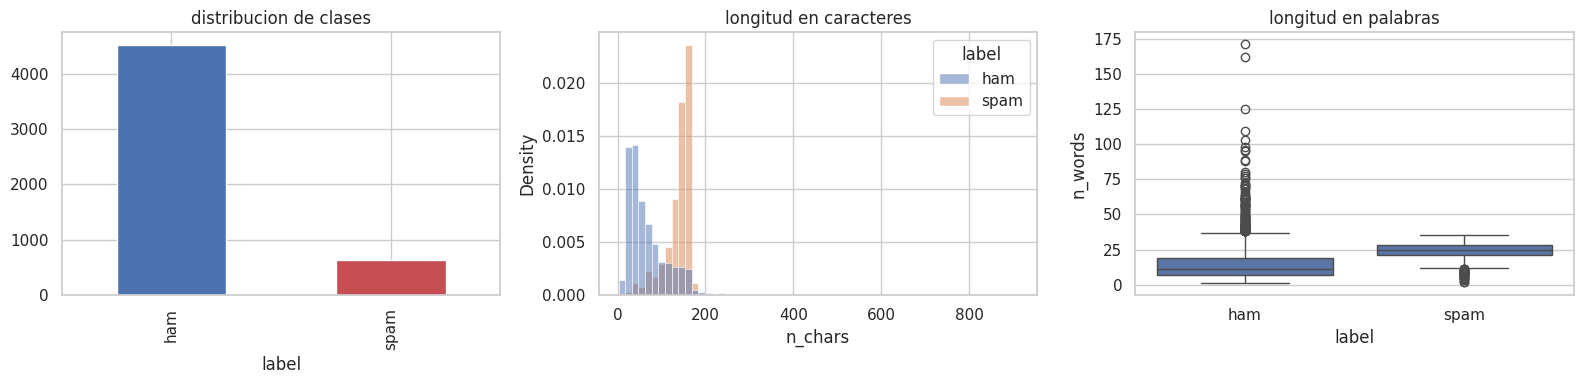

       n_chars  n_words
label                  
ham       53.0     11.0
spam     148.0     25.0


In [4]:
# los duplicados son informativos en spam suelen indicar campañas el mismo texto enviado masivamente
dups = df_raw[df_raw.duplicated("text", keep=False)]
print("mensajes duplicados por clase:\n", dups.label.value_counts(), "\n")

# se eliminan para evitar fuga de informacion el mismo texto en train y test
df = df_raw.drop_duplicates("text").reset_index(drop=True)
print("mensajes unicos:", len(df))
print(df.label.value_counts(normalize=True).mul(100).round(2).rename("% del total"))

df["n_chars"] = df.text.str.len()
df["n_words"] = df.text.str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.label.value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"], title="distribucion de clases")
sns.histplot(data=df, x="n_chars", hue="label", bins=60, ax=ax[1], stat="density", common_norm=False)
ax[1].set_title("longitud en caracteres")
sns.boxplot(data=df, x="label", y="n_words", ax=ax[2]); ax[2].set_title("longitud en palabras")
plt.tight_layout(); plt.show()

print(df.groupby("label")[["n_chars", "n_words"]].median())

### Analisis EDA
- desbalance de clases, ya que tras eliminar duplicados quedan 5.160 mensajes, 87,56 % ham y 12,44 % spam.
- la mediana del spam es de 148 caracteres y 25 palabras, frente a 53 caracteres y 11 palabras del ham, es decir, casi el triple, los 148 caracteres estan muy cerca del limite de 160 de un SMS
- duplicados como huella de campañas en valores hay más ham duplicado (503 mensajes) que spam (200), el 26,8 % del spam (200/747) pertenece a algun grupo de mensajes repetidos, frente al 10,4 % del ham (503/4.827), en el ham los duplicados corresponden a respuestas cortas y comunes ("Ok", "Sorry, I'll call later"), se eliminaron 414 duplicados para evitar que un mismo texto aparezca en entrenamiento y prueba, la idea de campaña se retoma en la seccion 14 con similitud semantica

## Normalizacion de texto
se busca transformar el texto para que variantes superficiales de lo mismo se traten igual, se incluye para decodificar html, normalizar Unicode NFKC, pasar a minusculas, reducir caracteres repetidos y eliminar puntuacion, en este caso los numeros de telefono, urls, correos y montos no se eliminan, se reemplazan por (phonetoken,urltoken,moneytoken), el numero casi nunca se repite, pero el numero premium es un indicador fuerte de fraude, esta tecnica se conoce como entity masking, el orden de los reemplazos se hace, primero correos, contienen puntos como las urls, luego urls, dinero antes que telefonos y telefonos antes que numeros sueltos

In [5]:
EMAIL_RE     = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
URL_RE       = re.compile(r"(https?://\S+|www\.\S+|\b[a-z0-9-]+\.(?:com|net|org|co\.uk|biz|info|co)\b\S*)", re.I)
MONEY_RE     = re.compile(r"([£$€]\s?\d[\d,]*(\.\d+)?)|(\b\d[\d,]*(\.\d+)?\s?(pounds|usd|gbp)\b)|(\b\d+(\.\d+)?(p|ppm)\b)", re.I)
PHONE_RE     = re.compile(r"\+?\d[\d\s.-]{7,}\d")#puntos como separador
SHORTCODE_RE = re.compile(r"\b\d{5,6}\b")#codigos cortos de sms premium
NUM_RE       = re.compile(r"\b\d+\b")

def light_clean(text):
    """limpieza que conserva mayusculas y puntuacion ya que la necesitan spacy y los transformer"""
    text = html.unescape(text)
    text = unicodedata.normalize("NFKC", text)
    return re.sub(r"\s+", " ", text).strip()

def normalize(text):
    """normalizacion completa para modelos basados en bolsa de palabras"""
    t = light_clean(text).lower()
    t = EMAIL_RE.sub(" emailtoken ", t)
    t = URL_RE.sub(" urltoken ", t)
    t = MONEY_RE.sub(" moneytoken ", t)
    t = PHONE_RE.sub(" phonetoken ", t)
    t = SHORTCODE_RE.sub(" shortcodetoken ", t)
    t = NUM_RE.sub(" numtoken ", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["clean"] = df.text.apply(light_clean)
df["norm"]  = df.text.apply(normalize)

for _, r in df[df.label == "spam"].sample(4, random_state=SEED).iterrows():
    print("ORIGINAL :", wrap(r.text)); print("NORMAL.  :", wrap(r.norm)); print("-" * 110)

ORIGINAL : 22 days to kick off! For Euro2004 U will be kept up to date with the latest news and results daily. To be
removed send GET TXT STOP to 83222
NORMAL.  : numtoken days to kick off for euro u will be kept up to date with the latest news and results daily to be
removed send get txt stop to shortcodetoken
--------------------------------------------------------------------------------------------------------------
ORIGINAL : Double Mins & Double Txt & 1/2 price Linerental on Latest Orange Bluetooth mobiles. Call MobileUpd8 for the
very latest offers. 08000839402 or call2optout/LF56
NORMAL.  : double mins double txt numtoken numtoken price linerental on latest orange bluetooth mobiles call mobileupd
for the very latest offers phonetoken or call optout lf
--------------------------------------------------------------------------------------------------------------
ORIGINAL : Bored housewives! Chat n date now! 0871750.77.11! BT-national rate 10p/min only from landlines!
NORMAL.  : b

In [6]:
#indicadores enmascarados
indicators = ["urltoken", "emailtoken", "phonetoken", "shortcodetoken", "moneytoken", "numtoken"]
rows = []
for ind in indicators:
    has = df.norm.str.contains(rf"\b{ind}\b")
    rows.append({"indicador": ind,
                 "% spam que lo contiene": has[df.label == "spam"].mean() * 100,
                 "% ham que lo contiene":  has[df.label == "ham"].mean() * 100})
ind_df = pd.DataFrame(rows).round(2)
display(ind_df)

#señales que la normalizacion elimina mayusculas y signos de exclamacion
df["upper_ratio"] = df.text.apply(lambda s: sum(c.isupper() for c in s) / max(1, sum(c.isalpha() for c in s)))
df["n_exclam"] = df.text.str.count("!")
display(df.groupby("label")[["upper_ratio", "n_exclam"]].mean().round(3))

,indicador,% spam que lo contiene,% ham que lo contiene
0,urltoken,17.76,0.20
1,emailtoken,0.93,0.02
2,phonetoken,56.07,0.07
3,shortcodetoken,31.93,0.00
4,moneytoken,52.02,0.29
5,numtoken,63.24,12.35


,upper_ratio,n_exclam
label,,
ham,0.077,0.178
spam,0.165,0.693


### Analisis normalizacion

el telefono separado por puntos es posiblemente una tecnica de evasion de filtros, los codigos cortos son los numeros de sms premium, caracteristicos del fraude por suscripcion, se ampliaron las regex (puntos como separador en telefonos y se verifico que un mensaje legitimo con horas y precios ("7.30", "2.50") no genera falsos indicadores


- indicadores mas fuertes, phonetoken (56,07 % spam frente a 0,07 % ham), moneytoken (52,02 % frente a 0,29 %) y shortcodetoken (31,93 % frente a 0 %), enmascarar los numeros en lugar de eliminarlos conserva la señal mas predictiva del corpus
- numtoken discrimina menos, el (63,24 % frente a 12,35 %) porque el ham tambien tiene horas y fechas, por eso es mejor separar los numeros con significado de fraude de los genericos
- validez externa,  el 0 % de shortcodetoken en ham es propio de este corpus
- urls solo aparecen en el 17,76 % del spam, porque en 2011 el fraude se monetizaba con numeros premium, el smishing actual se basa en enlaces, lo que limita la transferencia de este corpus
- costo de normalizar, el spam tiene el doble de mayusculas (0,165 frente a 0,077) y casi 4 veces mas "!" (0,693 frente a 0,178), pasar a minusculas y quitar la puntuacion elimina estas señales de urgencia.

## stemming

En este item se comparan tres algoritmos de NLTK, antes se tokeniza, se divide el texto en unidades, como el texto ya esta normalizado, solo necesita una expresion de secuencias alfabaticas

In [7]:
tokenizer = RegexpTokenizer(r"[a-z]+")
df["tokens"] = df.norm.apply(tokenizer.tokenize)

porter, snowball, lancaster = PorterStemmer(), SnowballStemmer("english"), LancasterStemmer()

words = ["winning", "winner", "wins", "claimed", "claiming", "congratulations", "verification",
         "verify", "accounts", "messages", "urgently", "prizes", "delivery", "delivered",
         "organization", "organ", "university", "universe", "generously", "general"]
display(pd.DataFrame({"palabra": words,
                      "Porter": [porter.stem(w) for w in words],
                      "Snowball": [snowball.stem(w) for w in words],
                      "Lancaster": [lancaster.stem(w) for w in words]}))

,palabra,Porter,Snowball,Lancaster
0,winning,win,win,win
1,winner,winner,winner,win
2,wins,win,win,win
3,claimed,claim,claim,claim
4,claiming,claim,claim,claim
5,congratulations,congratul,congratul,congrat
6,verification,verif,verif,ver
7,verify,verifi,verifi,ver
8,accounts,account,account,account
9,messages,messag,messag,mess


In [8]:
all_tokens = [t for toks in df.tokens for t in toks]
vocab = set(all_tokens)
res = {"sin stemming": len(vocab)}
for name, st in [("porter", porter), ("snowball", snowball), ("lancaster", lancaster)]:
    res[name] = len({st.stem(w) for w in vocab})
vocab_df = pd.DataFrame({"tamaño vocabulario": res})
vocab_df["reduccion %"] = (1 - vocab_df["tamaño vocabulario"] / res["sin stemming"]).mul(100).round(1)
display(vocab_df)

#casos de over-stemming raices que agrupan muchas palabras distintas
lanc_groups = {}
for w in vocab:
    lanc_groups.setdefault(lancaster.stem(w), set()).add(w)
worst = sorted(lanc_groups.items(), key=lambda kv: -len(kv[1]))[:5]
for stem, ws in worst:
    print(f"{stem!r:>10} <- {sorted(ws)[:12]}")

,tamaño vocabulario,reduccion %
sin stemming,7678,0.0
porter,6316,17.7
snowball,6321,17.7
lancaster,5648,26.4


     'act' <- ['act', 'acted', 'acting', 'action', 'activ', 'activate', 'active', 'activities', 'actor', 'actual', 'actually']
      'ar' <- ['ar', 'are', 'aren', 'arent', 'arise', 'arises', 'arr', 'arrival', 'arrive', 'arrived', 'arul']
     'fin' <- ['final', 'finalise', 'finally', 'finance', 'financial', 'fine', 'finish', 'finished', 'finishes', 'finishing', 'finn']
     'lov' <- ['lov', 'lovable', 'love', 'loved', 'lovely', 'lover', 'lovers', 'loves', 'loving', 'lovingly', 'lovly']
     'car' <- ['car', 'care', 'cared', 'career', 'careful', 'carefully', 'cares', 'caring', 'carlie', 'carly', 'cars']


### analisis stemming

Reduccion de vocabulario:Porter (6.316) y Snowball (6.321) reducen el vocabulario un 17,7 % frente a las 7.678 palabras originales, lancaster lo reduce un 26,4 % (5.648), a costa de mucho mas over-stemming

comparacion sobre palabras del dominio
- snowball corrige a porter distingue "generously" de "general", que porter une en gener
- under-stemming porter y snowball no unen variantes relacionadas: "verification" verif frente a "verify" verifi, y "delivery" deliveri frente a "delivered" deliv
- over-stemming los tres unen "organization" con "organ" y "university" con "universe"

Grupos mas grandes de lancaster, muestran que su reduccion adicional se debe en gran parte a errores:
- car une "car", "care", "career" y "carly".
- fin une "final", "finance", "fine" y "finish".
- ar une "are", "arrive" y "arise".
- act une "act" con "actually".
- solo lov (love, loved, lovely, loving)


##stopwords
busca eliminar palabras funcionales muy frecuentes ("the", "to", "you", "is") que en tareas de busqueda y topicos aportan poco contenido


Un valor > 0 indica que la palabra es más propia del spam y < 0, del ham

Stopwords NLTK: 198

% de tokens que son stopwords por clase:
label
ham     43.5
spam    29.4
dtype: float64


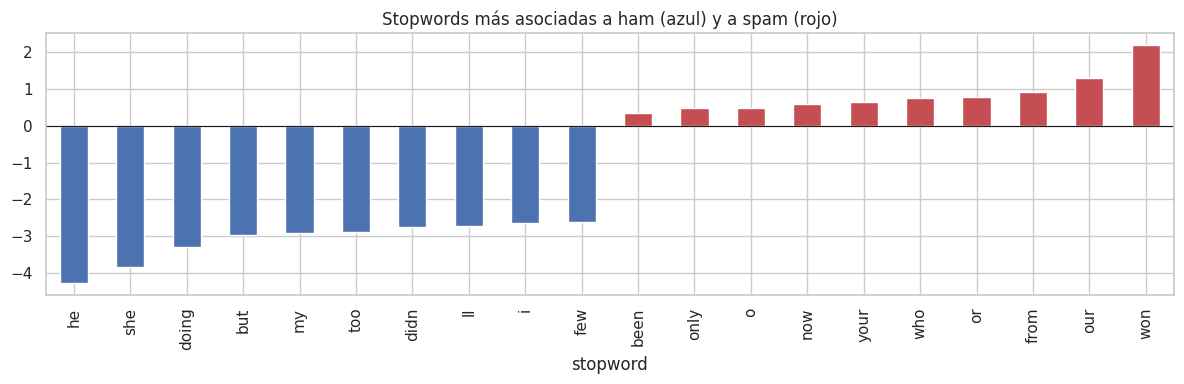

In [9]:
sw = set(stopwords.words("english"))
print("Stopwords NLTK:", len(sw))

df["tokens_nosw"] = df.tokens.apply(lambda ts: [t for t in ts if t not in sw])
df["stems"] = df.tokens_nosw.apply(lambda ts: [porter.stem(t) for t in ts])

share = df.apply(lambda r: 1 - len(r.tokens_nosw) / max(1, len(r.tokens)), axis=1)
print("\n% de tokens que son stopwords por clase:")
print(share.groupby(df.label).mean().mul(100).round(1))

cnt_spam = Counter(t for ts in df[df.label == "spam"].tokens for t in ts)
cnt_ham  = Counter(t for ts in df[df.label == "ham"].tokens for t in ts)
N_s, N_h, V = sum(cnt_spam.values()), sum(cnt_ham.values()), len(vocab)

def lor(w):
    return math.log(((cnt_spam[w] + 1) / (N_s + V)) / ((cnt_ham[w] + 1) / (N_h + V)))

sw_df = pd.DataFrame([{"stopword": w, "freq_spam": cnt_spam[w], "freq_ham": cnt_ham[w], "log_odds": lor(w)}
                      for w in sw if cnt_spam[w] + cnt_ham[w] >= 20]).sort_values("log_odds")
fig, ax = plt.subplots(figsize=(12, 4))
pd.concat([sw_df.head(10), sw_df.tail(10)]).plot.bar(x="stopword", y="log_odds", ax=ax, legend=False,
    color=["#4C72B0"] * 10 + ["#C44E52"] * 10)
ax.set_title("Stopwords más asociadas a ham (azul) y a spam (rojo)"); ax.axhline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

In [10]:
# stopwords de dominio abreviaturas tipicas de sms que la lista estandar no contempla
sms_sw = {"u", "ur", "im", "lt", "gt", "ok", "da", "lor", "ll", "dont", "wat", "gonna"}
print({w: round(lor(w), 2) for w in sorted(sms_sw) if cnt_spam[w] + cnt_ham[w] > 0})

{'da': -3.14, 'dont': -1.42, 'gonna': -2.95, 'gt': -0.26, 'im': -1.16, 'll': -2.72, 'lor': -3.95, 'lt': 0.03, 'ok': -2.63, 'u': -0.7, 'ur': 0.6, 'wat': -2.81}


### analisis stopwords

- proporcion el 43,5 % de los tokens del ham son stopwords frente al 29,4 % del spam, el ham es conversacional ("I'll be there in a bit") mientras que el spam esta cargado de terminos de contenido ("free", "prize", "claim")
- stopwords asociadas al spam "your" y "our" indican que el mensaje se dirige a la victima y que la supuesta empresa se presenta, "now" expresa urgencia, "been" aparece en frases como "you have been selected", "only" en "only £1" y "or" en "call or text"
- stopwords asociadas al ham predominan la primera y tercera persona ("i", "my", "he", "she"), propias de la conversacion entre conocidos, junto con restos de contracciones informales como "ll" y "didn"
- Hallazgo clave, "won",  es la stopword con mayor log hacia spam (≈ +2,2), NLTK la incluye por la contraccion "won't", pero tras la normalizacion no se distingue de "won" como pasado de win ("You have won a prize"), por lo que la lista estandar elimina la palabra central del fraude por premios
- abreviaturas de sms las propias de la conversacion entre conocidos son fuertemente de ham, "lor" (−3,95), "da" (−3,14), "gonna" (−2,95), "wat" (−2,81) y "ok" (−2,63), en cambio "ur" se inclina hacia spam (+0,6) porque los defraudadores tambien abrevian para aprovechar los 160 caracteres ("claim ur prize"), "u" apenas discrimina (−0,7) y "lt"/"gt" son restos de entidades html sin informacion, asi que anadirlas como stopwords de dominio eliminaria una de las senales mas claras del mensaje legitimo


## Term Frequency (TF)
se usa para medir cuantas veces aparece un termino en un documento, la variante sublineal es relevante en spam porque los estafadores repiten terminos para llamar la atencion

In [11]:
doc = df[df.label == "spam"].tokens_nosw.iloc[3]
print("documento:", " ".join(doc), "\n")
c = Counter(doc)
tf_doc = pd.DataFrame({"f_cruda": c}).assign(
    tf_relativa=lambda d: d.f_cruda / d.f_cruda.sum(),
    tf_log=lambda d: 1 + np.log(d.f_cruda)).sort_values("f_cruda", ascending=False).round(3)
display(tf_doc)

documento: mobile numtoken months u r entitled update latest colour mobiles camera free call mobile update co free phonetoken 



,f_cruda,tf_relativa,tf_log
mobile,2,0.111,1.693
update,2,0.111,1.693
free,2,0.111,1.693
months,1,0.056,1.000
u,1,0.056,1.000
r,1,0.056,1.000
numtoken,1,0.056,1.000
entitled,1,0.056,1.000
latest,1,0.056,1.000
mobiles,1,0.056,1.000


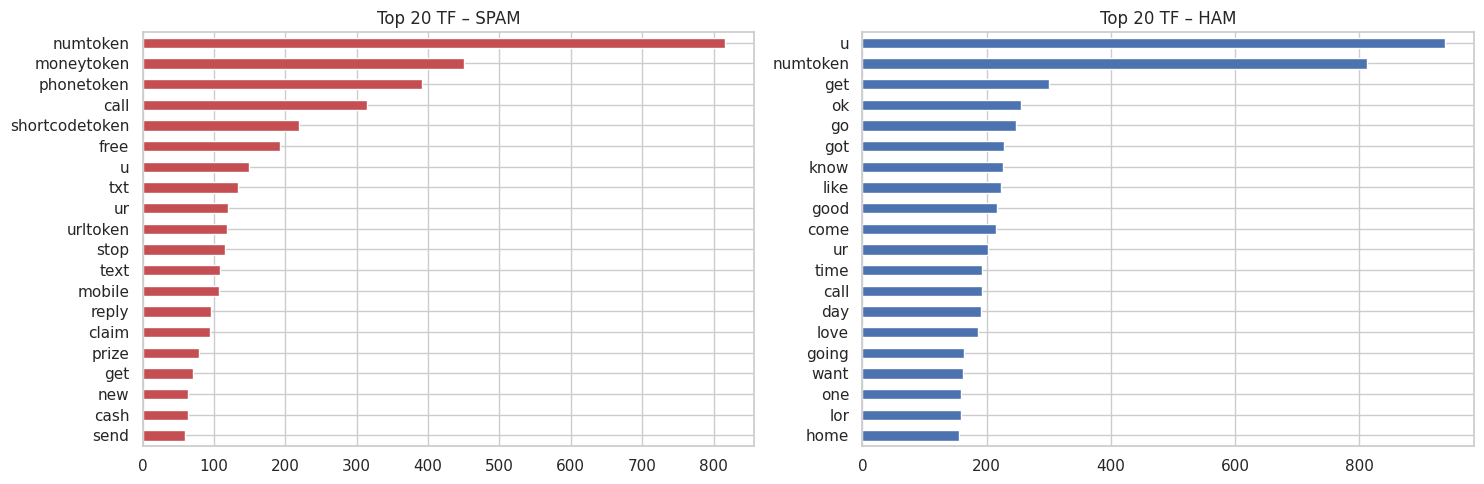

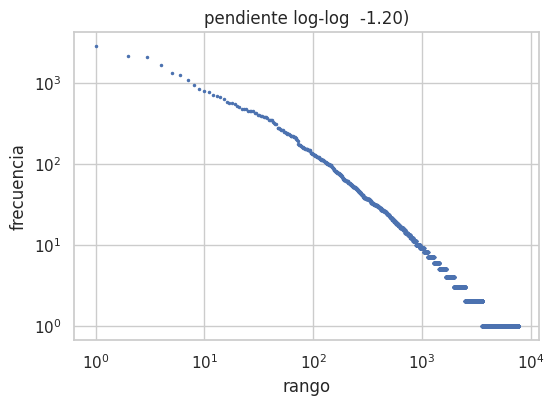

terminos que aparecen una sola vez (hapax): 53.3% del vocabulario


In [12]:
tf_spam = Counter(t for ts in df[df.label == "spam"].tokens_nosw for t in ts)
tf_ham  = Counter(t for ts in df[df.label == "ham"].tokens_nosw for t in ts)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
pd.Series(dict(tf_spam.most_common(20))).sort_values().plot.barh(ax=ax[0], color="#C44E52", title="Top 20 TF – SPAM")
pd.Series(dict(tf_ham.most_common(20))).sort_values().plot.barh(ax=ax[1], color="#4C72B0", title="Top 20 TF – HAM")
plt.tight_layout(); plt.show()

# Ley de Zipf: frecuencia ~ 1/rango
freqs = np.array(sorted(Counter(all_tokens).values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
slope = np.polyfit(np.log(ranks), np.log(freqs), 1)[0]
plt.figure(figsize=(6, 4)); plt.loglog(ranks, freqs, ".", ms=3)
plt.title(f"pendiente log-log  {slope:.2f})"); plt.xlabel("rango"); plt.ylabel("frecuencia"); plt.show()
print(f"terminos que aparecen una sola vez (hapax): {(freqs == 1).mean() * 100:.1f}% del vocabulario")

### Analisis (TF)

- documento individual, el mensaje tiene 18 tokens despues de quitar stopwords, "mobile", "update" y "free" aparecen dos veces (TF cruda 2, relativa 0,111) y el resto una vez (0,056), la repeticion se concentra en el mensaje (movil nuevo, actualizacion, gratis)
- Variantes de TF, la TF relativa corrige por longitud (2/18 = 0,111) y permite comparar mensajes cortos y largos, la TF logaritmica (1 + ln 2 = 1,693) reduce el peso de la repeticion, de modo que repetir "free" dos veces no cuenta el doble, lo que protege contra mensajes que repiten palabras de forma artificial, ademas "mobile" y "mobiles" se cuentan por separado porque aqui no se aplica stemming, con Snowball sumarian 3 apariciones
- top 20 del spam, reproduce el guion completo del fraude, el canal ("phonetoken" ≈ 390, "shortcodetoken" ≈ 220, "urltoken"), el gancho ("moneytoken" ≈ 450, "free", "prize", "cash", "claim", "new"), la llamada a la accion ("call" ≈ 315, "txt", "text", "reply", "send") y la baja ("stop"), esta ultima propia de las suscripciones premium que deben incluir una instruccion para darse de baja
- top 20 del ham es lenguaje cotidiano, verbos como ("get", "go", "got", "come", "going", "want", "know"), respuestas cortas ("ok"), afecto ("love", "home") y abreviaturas informales ("u" ≈ 935, "lor").
- sesgo por tamaño de clase "numtoken" tiene una frecuencia absoluta parecida en ambas clases (≈ 815 en spam y ≈ 810 en ham), pero el spam tiene 642 mensajes frente a 4.518 del ham, asi que por mensaje es casi siete veces mas frecuente en spam, la TF absoluta favorece a la clase mayoritaria y debe interpretarse en relacion con el numero de documentos
- dispersion el 53,3 % del vocabulario son terminos que aparecen una sola vez

##Inverse Document Frequency (IDF) y TF-IDF
IDF penaliza los terminos que aparecen en muchos documentos, porque discriminan poco, se implementa la versión suavizada de scikit-learn, primero se implementa IDF y luego se valida contra TfidfVectorizer

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

N = len(df)
doc_freq = Counter(t for ts in df.tokens_nosw for t in set(ts))
idf_manual = {t: math.log((1 + N) / (1 + d)) + 1 for t, d in doc_freq.items()}

tfidf_vec = TfidfVectorizer(analyzer=lambda toks: toks)   # los documentos ya vienen tokenizados
X_tfidf = tfidf_vec.fit_transform(df.tokens_nosw)
idf_sklearn = dict(zip(tfidf_vec.get_feature_names_out(), tfidf_vec.idf_))

diff = max(abs(idf_manual[t] - idf_sklearn[t]) for t in idf_manual)
print(f"maxima diferencia manual vs sklearn: {diff:.2e}  ->  {'OK, coinciden' if diff < 1e-9 else 'REVISAR'}")

idf_s = pd.Series(idf_manual).sort_values()
display(pd.DataFrame({"idf mas bajo (comunes)": idf_s.head(10).round(2).index,
                      "valor": idf_s.head(10).round(2).values,
                      "idf mas alto (raros)": idf_s.tail(10).index,
                      "valor ": idf_s.tail(10).round(2).values}))

maxima diferencia manual vs sklearn: 0.00e+00  ->  OK, coinciden


,idf mas bajo (comunes),valor,idf mas alto (raros),valor
0,numtoken,2.68,chgs,8.86
1,u,2.91,dental,8.86
2,call,3.42,lowes,8.86
3,phonetoken,3.65,heap,8.86
4,moneytoken,3.70,dump,8.86
5,get,3.70,salesman,8.86
6,ur,3.97,pity,8.86
7,go,3.99,suggestions,8.86
8,ok,4.02,bitching,8.86
9,know,4.10,jurong,8.86


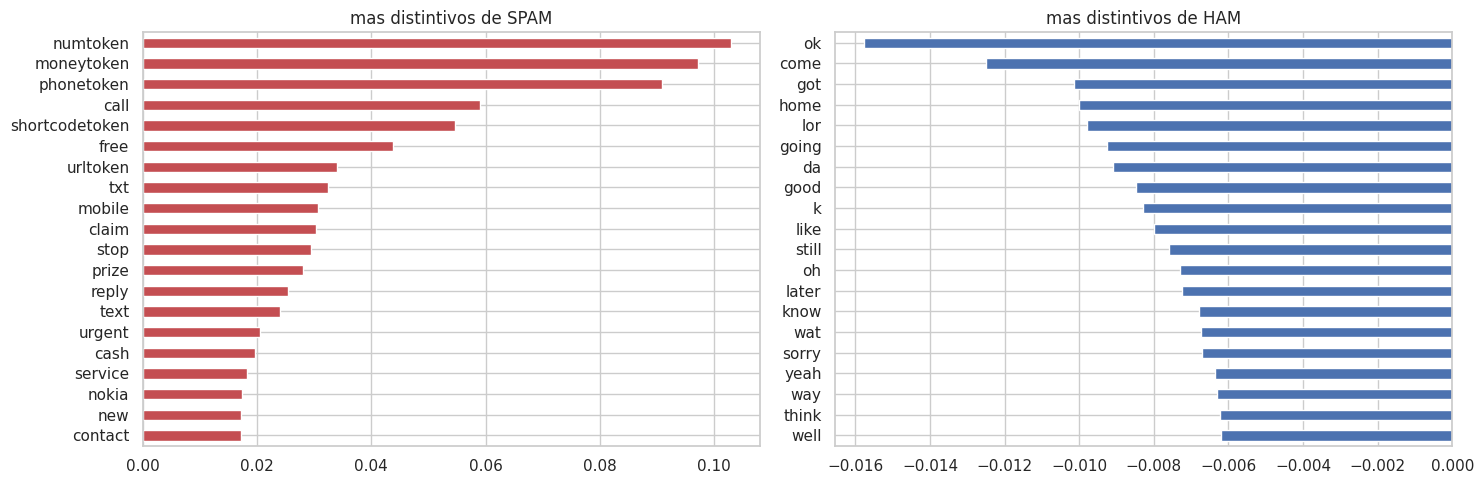

mensaje: SMS. ac Sptv: The New Jersey Devils and the Detroit Red Wings play Ice Hockey. Correct or Incorrect? End?
Reply END SPTV
top terminos TF-IDF: [('sptv', np.float64(0.502)), ('end', np.float64(0.335)), ('jersey', np.float64(0.251)), ('incorrect', np.float64(0.251)), ('wings', np.float64(0.251)), ('devils', np.float64(0.251))]


In [14]:
terms = tfidf_vec.get_feature_names_out()
mean_spam = np.asarray(X_tfidf[(df.label == "spam").values].mean(axis=0)).ravel()
mean_ham  = np.asarray(X_tfidf[(df.label == "ham").values].mean(axis=0)).ravel()
diff_tfidf = pd.Series(mean_spam - mean_ham, index=terms)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
diff_tfidf.nlargest(20).sort_values().plot.barh(ax=ax[0], color="#C44E52", title="mas distintivos de SPAM")
diff_tfidf.nsmallest(20).sort_values(ascending=False).plot.barh(ax=ax[1], color="#4C72B0", title="mas distintivos de HAM")
plt.tight_layout(); plt.show()

# Terminos clave de un mensaje concreto segun TF-IDF
i = df[df.label == "spam"].index[10]
row = X_tfidf[i].toarray().ravel()
print("mensaje:", wrap(df.text[i]))
print("top terminos TF-IDF:", [(terms[j], round(row[j], 3)) for j in row.argsort()[::-1][:6]])

### Analisis (IDF y TF-IDF)

- Validacion, la implementacion manual coincide exactamente con sklearn, diferencia 0,00
- IDF alto, el maximo (8,86) corresponde a terminos que aparecen en un solo documento, son hapax sin relacion con el fraude ("dental", "heap"), por lo que un IDF alto no implica utilidad
- IDF bajo, "numtoken" (2,68) y "u" (2,91) son los terminos mas extendidos, pero tambien "phonetoken" (3,65) y "moneytoken" (3,70), los mejores indicadores de fraude, porque IDF no conoce las etiquetas y los trata como comunes al aparecer en cientos de mensajes spam
-las diferencias del spam llegan a 0,10 y las del ham a −0,016, porque el spam repite plantillas con poco vocabulario y el ham reparte su peso entre miles de palabras

## part-of-speech (POS) Tagging
busca asignar a cada token su categoría gramatical (sustantivo, verbo, número...), se usa spacy, un modelo estadístico entrenado con ontonotes, que etiqueta según el contexto, por ejemplo, "call" puede ser verbo "call now" o sustantivo "a call", se procesa el corpus una sola vez y se reutilizan los documentos en POS, lematización, parsing y NER

In [15]:
nlp = spacy.load("en_core_web_sm")
docs = list(nlp.pipe(df.clean, batch_size=256))
print("Documentos procesados:", len(docs))

ex = docs[df[df.label == "spam"].index[0]]
print("Mensaje:", ex.text)
display(pd.DataFrame([(t.text, t.pos_, t.tag_, spacy.explain(t.tag_)) for t in ex],
                     columns=["token", "POS", "TAG", "significado"]))

Documentos procesados: 5160
Mensaje: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


,token,POS,TAG,significado
0,Free,ADJ,JJ,"adjective (English), other noun-modifier (Chinese)"
1,entry,NOUN,NN,"noun, singular or mass"
2,in,ADP,IN,"conjunction, subordinating or preposition"
3,2,NUM,CD,cardinal number
4,a,DET,DT,determiner
5,wkly,ADJ,JJ,"adjective (English), other noun-modifier (Chinese)"
6,comp,NOUN,NN,"noun, singular or mass"
7,to,PART,TO,"infinitival ""to"""
8,win,VERB,VB,"verb, base form"
9,FA,PROPN,NNP,"noun, proper singular"


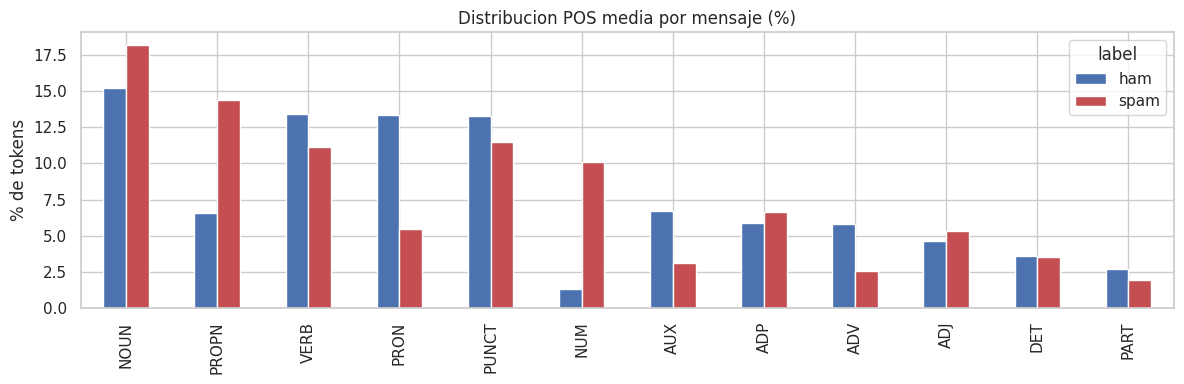

% de mensajes con al menos una oracion imperativa:
label
ham     19.1
spam    53.6
Name: imperative, dtype: float64


In [16]:
pos_rows = []
for d, lab in zip(docs, df.label):
    c = Counter(t.pos_ for t in d if not t.is_space)
    n = sum(c.values()) or 1
    pos_rows.append({**{k: v / n for k, v in c.items()}, "label": lab})
pos_df = pd.DataFrame(pos_rows).fillna(0)
pos_mean = pos_df.groupby("label").mean().T.mul(100)
pos_mean = pos_mean.loc[pos_mean.max(axis=1).sort_values(ascending=False).index[:12]]
pos_mean.plot.bar(figsize=(12, 4), color=["#4C72B0", "#C44E52"], title="Distribucion POS media por mensaje (%)")
plt.ylabel("% de tokens"); plt.tight_layout(); plt.show()

def is_imperative(sent):
    root = sent.root
    return root.tag_ == "VB" and not any(ch.dep_ in ("nsubj", "nsubjpass") for ch in root.children)

df["imperative"] = [any(is_imperative(s) for s in d.sents) for d in docs]
print("% de mensajes con al menos una oracion imperativa:")
print(df.groupby("label").imperative.mean().mul(100).round(1))

### Analisis (POS)

- el spam tiene casi 8 veces mas numeros y el doble de nombres propios, por los telefonos, codigos y montos y por las palabras en mayusculas que spacy etiqueta como nombres propios, el ham tiene mas pronombres, auxiliares y adverbios propios de la conversacion personal
- el 53,6 % del spam contiene al menos una oracion imperativa frente al 19,1 % del ham, aunque el ham usa mas verbos en general, el spam los usa para dar ordenes, un rasgo de ingenieria social que se mantiene aunque el estafador cambie el vocabulario
- en el mensaje de ejemplo "Text" se etiqueta como sustantivo cuando es el imperativo "Text FA to 87121", y la falta de espacios produce tokens mal formados, que ocultan el telefono y la restriccion de edad


## 8. Lematizacion
Busca reducir cada palabra a su lema, su forma de diccionario "won" = "win", a diferencia del stemming, usa diccionario y POS, por eso produce palabras reales y resuelve irregulares, pero es mas lento y depende de la calidad del etiquetado

In [17]:
compare_words = ["won", "winning", "prizes", "was", "better", "claimed", "delivery", "texting", "mice", "running"]
lemma_of = {}
for w in compare_words:
    lemma_of[w] = nlp(w)[0].lemma_# palabra aislada
display(pd.DataFrame({"palabra": compare_words,
                      "stem (Porter)": [porter.stem(w) for w in compare_words],
                      "lema (spaCy)": [lemma_of[w] for w in compare_words]}))

#lema depende del contexto "saw" como verbo vs como sustantivo
for s in ["I saw the message yesterday", "He bought a new saw"]:
    print(s, "->", [(t.text, t.pos_, t.lemma_) for t in nlp(s) if t.text == "saw"])

,palabra,stem (Porter),lema (spaCy)
0,won,won,win
1,winning,win,win
2,prizes,prize,prize
3,was,wa,be
4,better,better,well
5,claimed,claim,claim
6,delivery,deliveri,delivery
7,texting,text,texting
8,mice,mice,mouse
9,running,run,run


I saw the message yesterday -> [('saw', 'VERB', 'see')]
He bought a new saw -> [('saw', 'NOUN', 'saw')]


In [18]:
df["lemmas"] = [[t.lemma_.lower() for t in d if t.is_alpha and not t.is_stop] for d in docs]

v_tok  = len({t for ts in df.tokens_nosw for t in ts})
v_stem = len({t for ts in df.stems for t in ts})
v_lem  = len({t for ts in df.lemmas for t in ts})
display(pd.DataFrame({"vocabulario": [v_tok, v_stem, v_lem]},
                     index=["tokens (sin stopwords)", "stems Porter", "lemas spaCy"]))

i = df[df.label == "spam"].index[5]
print("Original:", df.text[i]); print("Stems   :", df.stems[i]); print("Lemas   :", df.lemmas[i])

,vocabulario
tokens (sin stopwords),7534
stems Porter,6208
lemas spaCy,6175


Original: URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C www.dbuk.net LCCLTD POBOX 4403LDNW1A7RW18
Stems   : ['urgent', 'numtoken', 'week', 'free', 'membership', 'moneytoken', 'prize', 'jackpot', 'txt', 'word', 'claim', 'shortcodetoken', 'c', 'urltoken', 'lccltd', 'pobox', 'ldnw', 'rw']
Lemas   : ['urgent', 'win', 'week', 'free', 'membership', 'prize', 'jackpot', 'txt', 'word', 'claim', 'lccltd', 'pobox']


### Analisis lematizacion

- la lematizacion resuelve lo que el stemming no puede, ademas siempre devuelve palabras reales
- "saw" se lematiza como "see" cuando es verbo y como "saw" cuando es sustantivo, el stemming no puede hacer esa distincion, pero sin contexto el lematizador tambien falla, "texting" queda sin reducir
- los lemas reducen el vocabulario, aunque no son del todo comparables porque los lemas se calculan sobre el texto original con las stopwords de spacy y los stems sobre el texto normalizado



## Parsing
busca identificar la estructura gramatical de la oracion como un arbol en el que cada palabra depende de un nucleo


In [19]:
i = df[(df.label == "spam") & (df.n_words < 25)].index[2]
print(df.clean[i])
display(pd.DataFrame([(t.text, t.dep_, spacy.explain(t.dep_), t.head.text) for t in docs[i]],
                     columns=["token", "dependencia", "significado", "núcleo (head)"]))

SMS. ac Sptv: The New Jersey Devils and the Detroit Red Wings play Ice Hockey. Correct or Incorrect? End? Reply END SPTV


,token,dependencia,significado,núcleo (head)
0,SMS,ROOT,root,SMS
1,.,punct,punctuation,SMS
2,ac,compound,compound,Sptv
3,Sptv,dep,unclassified dependent,play
4,:,punct,punctuation,Sptv
5,The,det,determiner,Devils
6,New,compound,compound,Jersey
7,Jersey,compound,compound,Devils
8,Devils,nsubj,nominal subject,play
9,and,cc,coordinating conjunction,Devils


In [20]:
def verb_object_pairs(d):
    return [(t.head.lemma_.lower(), t.lemma_.lower()) for t in d
            if t.dep_ in ("dobj", "obj") and t.head.pos_ == "VERB"]

vo_spam = Counter(p for d, l in zip(docs, df.label) if l == "spam" for p in verb_object_pairs(d))
vo_ham  = Counter(p for d, l in zip(docs, df.label) if l == "ham"  for p in verb_object_pairs(d))
display(pd.DataFrame({"SPAM verbo→objeto": [f"{v} → {o} ({c})" for (v, o), c in vo_spam.most_common(15)],
                      "HAM verbo→objeto":  [f"{v} → {o} ({c})" for (v, o), c in vo_ham.most_common(15)]}))

chunks_spam = Counter(ch.root.lemma_.lower() for d, l in zip(docs, df.label) if l == "spam" for ch in d.noun_chunks)
print("nucleos de sintagmas nominales mas frecuentes en spam:", chunks_spam.most_common(15))

,SPAM verbo→objeto,HAM verbo→objeto
0,send → stop (20),call → i (54)
1,contact → you (15),tell → i (41)
2,win → prize (13),do → what (38)
3,draw → show (12),miss → you (38)
4,call → 08000930705 (11),see → you (38)
5,call → code (11),have → day (33)
6,call → mobileupd8 (9),take → care (28)
7,show → point (9),love → you (27)
8,receive → award (8),do → it (26)
9,win → cash (7),call → you (24)


nucleos de sintagmas nominales mas frecuentes en spam: [('you', 252), ('u', 99), ('i', 72), ('call', 58), ('prize', 57), ('text', 55), ('we', 51), ('ur', 50), ('tone', 49), ('reply', 47), ('mobile', 43), ('cash', 43), ('stop', 43), ('phone', 43), ('service', 42)]


### Analisis (parsing)

- el parser identifica bien la estructura de la oracion central, pero divide el mensaje en cuatro oraciones y analiza "Reply END SPTV" como un compuesto nominal en lugar de un imperativo
- los pares verbo objeto resumen las tacticas del fraude, darse de baja de una suscripcion, reclamar un premio y llamar a un numero
- el parsing aporta informacion estructurada que la bolsa de palabras pierde, saber que se pide "llamar a un numero" o "reclamar un premio" permite construir reglas explicables

## Named Entity Recognition (NER)
busca detectar y clasificar entidades del texto: personas (PERSON), organizaciones (ORG), dinero (MONEY), fechas (DATE), cantidades (CARDINAL), lugares (GPE)...


In [21]:
for i in df[df.label == "spam"].index[[1, 7, 12]]:
    displacy.render(docs[i], style="ent", jupyter=True)

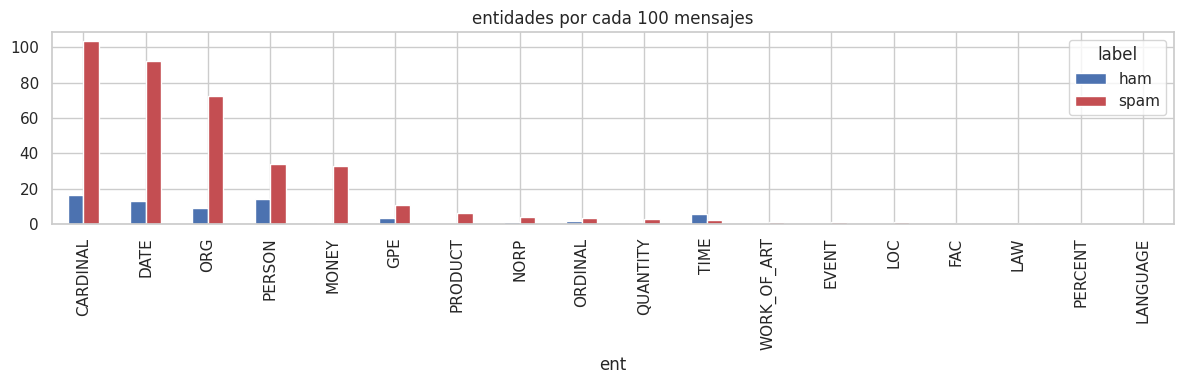


Ejemplos MONEY en spam: {'1000': 24, '5000': 16, '2000': 15, '1.50': 14, '500': 13, '100': 13, '250': 12, '350': 10, '2,000': 8, '150': 6, '3': 6, '200': 5}

Ejemplos ORG en spam: {'FREE': 39, 'T&C': 17, 'U': 13, 'SAE': 12, 'WIN': 8, 'SavaMob': 8, 'MUSIC': 8, 'U. Todays': 7, 'Bonus Caller Prize': 7, 'PO Box': 6, 'SMS': 6, 'PO': 5}


In [22]:
ent_df = pd.DataFrame([{"label": lab, "ent": e.label_, "text": e.text}
                       for d, lab in zip(docs, df.label) for e in d.ents])
n_by_class = df.label.value_counts()
ent_rate = ent_df.groupby(["ent", "label"]).size().unstack(fill_value=0).div(n_by_class, axis=1).mul(100)
ent_rate = ent_rate.sort_values("spam", ascending=False)
ent_rate.plot.bar(figsize=(12, 4), color=["#4C72B0", "#C44E52"], title="entidades por cada 100 mensajes")
plt.tight_layout(); plt.show()

for lab in ["MONEY", "ORG"]:
    print(f"\nEjemplos {lab} en spam:", ent_df[(ent_df.ent == lab) & (ent_df.label == "spam")].text.value_counts().head(12).to_dict())

### Analisis (NER)

- el spam tiene muchas mas entidades por mensaje que el ham, la unica entidad mas frecuente en ham es TIME, que corresponde a planes cotidianos
- money es la entidad mas especifica del fraude, casi inexistente en ham, y sus valores mas comunes muestran la promesa economica tipica de los premios falsos
- errores en date, parte de su frecuencia en spam es falsa, el modelo etiqueta el telefono "09066364589" y la restriccion "16+" como fechas, por lo que date  esta inflado por numeros que no son fechas
- las organizaciones mas frecuentes del spam son palabras en mayusculas como "FREE", "WIN", "MUSIC" y "U", o fragmentos legales como "T&C" y "PO Box", el modelo aprendio en texto periodistico que las mayusculas suelen ser organizaciones y ese sesgo no se transfiere al SMS
- el NER generico sirve como señal agregada, porque el spam concentra entidades numericas y economicas, pero no es confiable para extraer indicadores concretos

## generacion de texto usando un LLM (instruction-tuned)
es un large language model ajustado con instrucciones que recibe una tarea en lenguaje natural y genera una respuesta, se usa Qwen2.5-Instruct, se usa decodificacion greedy para que el resultado sea reproducible.

In [23]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct" if USE_CUDA else "Qwen/Qwen2.5-0.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_ID)
llm = AutoModelForCausalLM.from_pretrained(LLM_ID, torch_dtype=torch.float16 if USE_CUDA else torch.float32).to(TORCH_DEVICE)
llm.eval()
print("modelo cargado:", LLM_ID)

SYSTEM_PROMPT = (
    "Eres un analista de ciberseguridad especializado en fraude por SMS (smishing). "
    "Analiza el mensaje y responde SIEMPRE en español con exactamente este formato:\n"
    "Veredicto: FRAUDE o LEGITIMO\n"
    "Indicadores: lista breve de señales observadas\n"
    "Tecnica de ingenieria social: nombre de la tecnica o 'ninguna'\n"
    "Recomendacion: una frase para el usuario"
)

def llm_generate(messages, max_new_tokens=200):
    prompt = llm_tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = llm_tok(prompt, return_tensors="pt").to(TORCH_DEVICE)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                           pad_token_id=llm_tok.eos_token_id)
    return llm_tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def analyze_sms(msg):
    return llm_generate([{"role": "system", "content": SYSTEM_PROMPT},
                         {"role": "user", "content": f'Mensaje SMS: "{msg}"'}])

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

modelo cargado: Qwen/Qwen2.5-1.5B-Instruct


In [24]:
sample_llm = pd.concat([df[df.label == "spam"].sample(4, random_state=1),
                        df[df.label == "ham"].sample(4, random_state=1)])
llm_results = []
for _, r in sample_llm.iterrows():
    out = analyze_sms(r.clean)
    pred = "spam" if "FRAUDE" in out.upper().split("\n")[0] else "ham"
    llm_results.append({"real": r.label, "pred_llm": pred})
    print(f"[REAL: {r.label.upper()}] {wrap(r.clean)}\n{out}\n" + "=" * 110)

llm_eval = pd.DataFrame(llm_results)
print(f"Acierto del LLM en {len(llm_eval)} mensajes: {(llm_eval.real == llm_eval.pred_llm).mean():.0%}")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


[REAL: SPAM] FREE entry into our £250 weekly comp just send the word ENTER to 84128 NOW. 18 T&C www.textcomp.com cust care
08712405020.
Veredicto: FRAUDE

Indicadores: 
- Ofrece un premio económico inmediato sin requisitos previos.
- Solicita envío de texto a un número fijo.
- Utiliza palabras como "FREE" y "NOW", sugiriendo urgencia.

Tecnica de ingeniería social: Ingeniería social directa

Recomendación: No hagas clic ni envíe ningún texto a ese número. Este es probablemente un intento de engaño.
[REAL: SPAM] 3. You have received your mobile content. Enjoy
Veredicto: LEGITIMO

Indicadores: El mensaje no contiene ninguna amenaza, promesa inverosímil ni solicita información personal.

Tecnica de ingeniería social: Ingeniería social

Recomendación: No hagas clic en ningún enlace que te envíen a través del mensaje. Verifica directamente el sitio web oficial de tu proveedor de servicios de contenido móvil.
[REAL: SPAM] If you don't, your prize will go to another customer. T&C at www.t-c.b

In [25]:
# concientizacion para usuarios finales
print(llm_generate([{"role": "user", "content":
    "Redacta un mensaje corto (máximo 4 frases) para clientes de un banco explicando "
    "como reconocer un SMS fraudulento que pide actualizar datos, y que hacer si lo reciben."}],
    max_new_tokens=180))

Aquí tienes una redacción corta para los clientes del banco:

1. Recuerda siempre verificar la fuente antes de responder.
2. No envíes información personal por SMS sin confirmar su origen.
3. Si reciviste un SMS solicitando actualizaciones de datos bancarios, es probable que sea un fraude.
4. Contacta al banco directamente o verifica el número en tu cuenta para confirmar.

Estos puntos ayudan a prevenir el fraude y proteger tus datos financieros.


### Analisis generacion con LLM

- el modelo acierta 3 de 8 mensajes, detecta 3 de los 4 spam pero clasifica como fraude los 4 mensajes legitimos
- en el primer spam identifica señales reales, el premio de £250, la instruccion de enviar un texto a un numero y las palabras de urgencia "FREE" y "NOW"
- inventa indicadores que no estan en el mensaje, como "apagones de energia" en un anuncio de citas, "solicita informacion personal" o "URL insegura" sin evidencia, y en el ham convierte rasgos normales en sospechosos
- en el spam que no detecta ("You have received your mobile content") responde LEGITIMO pero igual asigna una tecnica de ingenieria social y recomienda no hacer clic, y la tecnica es casi siempre la etiqueta generica "Ingenieria social", sin distinguir entre urgencia, recompensa o suplantacion
- Texto de concientizacion: es correcto y util, verificar la fuente, no enviar datos por SMS, contactar al banco por canales oficiales


In [26]:
del llm; gc.collect()
if USE_CUDA: torch.cuda.empty_cache()

## Question Answering
en un contexto y con una pregunta, el modelo extrae el fragmento del texto que responde, es extractivo, no genera texto nuevo, solo señala un intervalo inicio y fin dentro del contexto,se usa deepset/xlm-roberta-base-squad2, entrenado en SQuAD 2.0, que incluye preguntas sin respuesta

In [27]:
from transformers import pipeline

qa = pipeline("question-answering", model="deepset/xlm-roberta-base-squad2", device=DEVICE)

BOLETIN = (
    "BOLETÍN DE INTELIGENCIA DE AMENAZAS FD-2026-014. Entre el 2 y el 9 de septiembre de 2026 se detectó "
    "una campaña de smishing que suplanta al Banco Andino, una entidad financiera ficticia usada en este ejercicio. "
    "Los mensajes se enviaron desde el número +57 300 000 0000 e informaban al destinatario que su cuenta sería "
    "bloqueada en 24 horas si no actualizaba sus datos. El enlace dirigía al dominio malicioso "
    "banco-andino-verificacion[.]example, registrado el 1 de septiembre de 2026 y alojado en un proveedor extranjero. "
    "El sitio clonaba la página de inicio de sesión de la banca en línea y solicitaba usuario, contraseña y el código OTP. "
    "Hasta el 9 de septiembre, 312 usuarios reportaron haber recibido el mensaje y 27 confirmaron haber ingresado sus "
    "credenciales. La técnica principal es la ingeniería social basada en urgencia y miedo a perder el acceso a la cuenta "
    "(MITRE ATT&CK T1566, Phishing). Se recomienda bloquear el dominio, solicitar su baja al registrador y emitir una "
    "alerta a los clientes."
)

preguntas = [
    "¿Qué entidad suplanta la campaña?",
    "¿Desde qué número se enviaron los mensajes?",
    "¿Cuál es el dominio malicioso?",
    "¿Qué datos solicitaba el sitio falso?",
    "¿Cuántos usuarios ingresaron sus credenciales?",
    "¿Qué técnica de MITRE ATT&CK se usó?",
    "¿Qué grupo criminal está detrás de la campaña?",   # NO está en el texto
]
qa_rows = []
for q in preguntas:
    r = qa(question=q, context=BOLETIN, handle_impossible_answer=True)
    qa_rows.append({"pregunta": q, "respuesta": r["answer"] or "(sin respuesta en el texto)", "confianza": round(r["score"], 3)})
display(pd.DataFrame(qa_rows))

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/79.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda:0


,pregunta,respuesta,confianza
0,¿Qué entidad suplanta la campaña?,"Banco Andino,",0.956
1,¿Desde qué número se enviaron los mensajes?,+57 300 000 0000,0.859
2,¿Cuál es el dominio malicioso?,"banco-andino-verificacion[.]example,",0.878
3,¿Qué datos solicitaba el sitio falso?,(sin respuesta en el texto),0.918
4,¿Cuántos usuarios ingresaron sus credenciales?,27,0.884
5,¿Qué técnica de MITRE ATT&CK se usó?,(sin respuesta en el texto),0.254
6,¿Qué grupo criminal está detrás de la campaña?,(sin respuesta en el texto),0.561


### Analisis (question answering)

- el modelo extrae correctamente 4 indicadores con confianza alta, la entidad suplantada ("Banco Andino", 0,956), el numero de envio, el dominio malicioso en formato defanged y el numero de victimas, lo que permite convertir un boletin en respuestas puntuales para el analista
- el boletin no menciona ningun grupo criminal y el modelo responde correctamente que no hay respuesta, en lugar de inventar un nombre, que es la principal ventaja del QA extractivo frente a un LLM generativo
- la tecnica MITRE (T1566) tambien esta en el texto, pero la confianza cae a 0,254, porque el boletin menciona dos posibles "tecnicas", la ingenieria social basada en urgencia y T1566 entre parentesis, y el modelo reparte la probabilidad entre ambas
- el modelo acierta 5 de 7 preguntas (4 extracciones y 1 ausencia correcta), pero la confianza del "sin respuesta" no es fiable por si sola, en un flujo real conviene revisar manualmente las preguntas sin respuesta y las de confianza baja, sobre todo cuando se buscan indicadores que luego se usaran para bloquear o reportar

## 13. Summarization (resumen automatico)
Se comparan dos enfoques:
- Extractivo en que se seleccionan las oraciones mas importantes del original,se implementa y  el puntaje de cada oracion es el promedio TF-IDF de sus palabras
- Abstractivo ya que el modelo seq2seq redacta un resumen con palabras propias


In [28]:
ADVISORY_EN = (
    "Security advisory FD-2026-014. Between September 2 and September 9, 2026, analysts detected an SMS phishing campaign "
    "impersonating Banco Andino, a fictitious bank used in this exercise. The messages were sent from the number "
    "+57 300 000 0000 and warned recipients that their account would be blocked within 24 hours unless they updated their "
    "information. The link pointed to the malicious domain banco-andino-verificacion.example, which was registered on "
    "September 1 and hosted by a foreign provider. The website cloned the online banking login page and requested the "
    "username, password and one-time password. By September 9, 312 customers had reported receiving the message and 27 "
    "confirmed that they had entered their credentials. The campaign relies on social engineering based on urgency and fear "
    "of losing access to the account. The domain has been reported to the registrar for takedown. Customers should never "
    "share one-time passwords and should access the bank only through the official application."
)
IOCS = ["banco-andino-verificacion.example", "+57 300 000 0000", "24 hours", "312", "27", "one-time password"]

def extractive_summary(text, n=3):
    sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if s.strip()]
    vec = TfidfVectorizer(stop_words="english").fit(sents)
    scores = np.asarray(vec.transform(sents).mean(axis=1)).ravel()
    keep = sorted(scores.argsort()[::-1][:n])       # conservar el orden original
    return " ".join(sents[i] for i in keep)

summarizer = pipeline("summarization", model="sshleifer/distilbart-cnn-12-6", device=DEVICE)
abstractive = summarizer(ADVISORY_EN, max_length=90, min_length=35, do_sample=False)[0]["summary_text"]
extractive = extractive_summary(ADVISORY_EN)

def ioc_retention(summary):
    return sum(ioc.lower() in summary.lower() for ioc in IOCS) / len(IOCS)

summ_eval = pd.DataFrame([
    {"metodo": "Extractivo (TF-IDF)", "palabras": len(extractive.split()),
     "compresion": len(extractive.split()) / len(ADVISORY_EN.split()), "retención IOCs": ioc_retention(extractive)},
    {"metodo": "Abstractivo (DistilBART)", "palabras": len(abstractive.split()),
     "compresion": len(abstractive.split()) / len(ADVISORY_EN.split()), "retención IOCs": ioc_retention(abstractive)},
]).round(2)
print("EXTRACTIVO:\n", wrap(extractive), "\n\nABSTRACTIVO:\n", wrap(abstractive), "\n")
display(summ_eval)

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cuda:0


EXTRACTIVO:
 Between September 2 and September 9, 2026, analysts detected an SMS phishing campaign impersonating Banco
Andino, a fictitious bank used in this exercise. The messages were sent from the number +57 300 000 0000 and
warned recipients that their account would be blocked within 24 hours unless they updated their information.
The link pointed to the malicious domain banco-andino-verificacion.example, which was registered on September
1 and hosted by a foreign provider. 

ABSTRACTIVO:
  An SMS phishing campaign impersonated Banco Andino, a fictitious bank used in this exercise . The messages
were sent from the number +57 300 000 0000 and warned recipients that their account would be blocked within 24
hours unless they updated their information . The campaign relies on social engineering based on urgency and
fear of losing access to the account . 



,metodo,palabras,compresion,retención IOCs
0,Extractivo (TF-IDF),71,0.47,0.50
1,Abstractivo (DistilBART),62,0.41,0.33


### Analisis (summarization)

- el resumen extractivo conserva 3 de 6 indicadores, el telefono, el plazo de 24 horas y el dominio malicioso, mientras que el abstractivo conserva solo 2 porque omite el dominio, que es el indicador mas importante para bloquear la campaña
- ninguno de los dos conserva el numero de usuarios afectados (312), las victimas que ingresaron credenciales (27) ni el robo del codigo OTP, es decir, ambos resumen el ataque pero no su alcance
- es mas corto y agrega la tecnica de ingenieria social basada en urgencia, pero casi no redacta con palabras propias, copia las primeras oraciones del texto, aunque no altero ninguna cifra ni invento datos
- selecciona tres oraciones completas que coinciden con las primeras del texto no puede alterar datos porque copia literalmente, pero deja fuera las oraciones de impacto y de recomendaciones

In [29]:
del summarizer, qa; gc.collect()
if USE_CUDA: torch.cuda.empty_cache()

##sentence Similarity (similitud semantica)
busca medir que tan parecidos son dos textos en significado, un modelo convierte cada mensaje en un vector de 384 dimensiones, y la similitud se calcula como coseno entre vectores

se hacen tres experimentos:
1. lexico frente a semantico:TF-IDF contra embeddings en parafrasis
2. busqueda semantica:dado un SMS nuevo, encontrar los mensajes historicos más parecidos
3. deteccion de campañas:agrupar spam casi identico, es decir, variaciones de una misma plantilla

In [30]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

st_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=TORCH_DEVICE)
emb = st_model.encode(df.clean.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
print("Matriz de embeddings:", emb.shape)

pairs = [
    ("Your bank account has been suspended, verify your details now",
     "We have blocked your card. Confirm your information immediately"),#parafrasis
    ("Your bank account has been suspended, verify your details now",
     "I will be late for dinner, keep some food for me"),#no relacionadas
    ("You won a free cruise, call now to claim",
     "Congratulations! You have been selected for a holiday prize, ring us today"),
]
tfidf_sim_vec = TfidfVectorizer().fit(df.norm)
sim_rows = []
for a, b in pairs:
    lex = cosine_similarity(tfidf_sim_vec.transform([normalize(a)]), tfidf_sim_vec.transform([normalize(b)]))[0, 0]
    sem = float(st_model.encode([a], normalize_embeddings=True) @ st_model.encode([b], normalize_embeddings=True).T)
    sim_rows.append({"texto A": a, "texto B": b, "coseno TF-IDF": round(lex, 3), "coseno embeddings": round(sem, 3)})
display(pd.DataFrame(sim_rows))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Matriz de embeddings: (5160, 384)


,texto A,texto B,coseno TF-IDF,coseno embeddings
0,"Your bank account has been suspended, verify your details now",We have blocked your card. Confirm your information immediately,0.132,0.588
1,"Your bank account has been suspended, verify your details now","I will be late for dinner, keep some food for me",0.000,0.180
2,"You won a free cruise, call now to claim","Congratulations! You have been selected for a holiday prize, ring us today",0.022,0.389


In [31]:
queries = ["URGENT: your parcel is held at customs, pay the £2 fee here to release it",
           "Congrats! You've been chosen for a $500 gift card. Reply YES to claim",
           "hey are we still meeting for lunch tomorrow?"]
q_emb = st_model.encode(queries, normalize_embeddings=True)
for q, qe in zip(queries, q_emb):
    sims = emb @ qe
    top = sims.argsort()[::-1][:5]
    vote = (df.label.values[top] == "spam").mean()
    print(f"\nCONSULTA: {q}\n  -> voto k-NN (k=5): {vote:.0%} spam")
    for j in top:
        print(f"   {sims[j]:.3f} [{df.label[j]}] {df.clean[j][:95]}")


CONSULTA: URGENT: your parcel is held at customs, pay the £2 fee here to release it
  -> voto k-NN (k=5): 100% spam
   0.487 [spam] Great News! Call FREEFONE 08006344447 to claim your guaranteed £1000 CASH or £2000 gift. Speak 
   0.479 [spam] URGENT!! Your 4* Costa Del Sol Holiday or £5000 await collection. Call 09050090044 Now toClaim.
   0.478 [spam] Urgent -call 09066649731from Landline. Your complimentary 4* Ibiza Holiday or £10,000 cash awai
   0.466 [spam] Urgent! Please call 09061213237 from a landline. £5000 cash or a 4* holiday await collection. T
   0.463 [spam] Urgent! call 09066350750 from your landline. Your complimentary 4* Ibiza Holiday or 10,000 cash

CONSULTA: Congrats! You've been chosen for a $500 gift card. Reply YES to claim
  -> voto k-NN (k=5): 100% spam
   0.598 [spam] You have won ?1,000 cash or a ?2,000 prize! To claim, call09050000327
   0.574 [spam] You have won ?1,000 cash or a ?2,000 prize! To claim, call09050000327. T&C: RSTM, SW7 3SS. 150p
   0.566 [sp

In [33]:
from sklearn.cluster import AgglomerativeClustering

spam_idx = np.where(df.label == "spam")[0]
clust = AgglomerativeClustering(n_clusters=None, metric="cosine", linkage="average",
                                distance_threshold=0.2).fit(emb[spam_idx])
sizes = pd.Series(clust.labels_).value_counts()
print(f"Spam unicos: {len(spam_idx)} | clusters: {len(sizes)} | clusters con ≥3 mensajes (campañas): {(sizes >= 3).sum()}")
print(f"% de spam que pertenece a una campaña (cluster ≥3): {sizes[sizes >= 3].sum() / len(spam_idx):.1%}")

for c in sizes.index[:3]:
    members = spam_idx[clust.labels_ == c]
    print(f"\n=== Campaña {c} ({len(members)} variantes) ===")
    for j in members[:4]:
        print("  •", df.clean[j][:110])

Spam unicos: 642 | clusters: 422 | clusters con ≥3 mensajes (campañas): 44
% de spam que pertenece a una campaña (cluster ≥3): 32.9%

=== Campaña 11 (18 variantes) ===
  • URGENT! Your Mobile No. was awarded £2000 Bonus Caller Prize on 5/9/03 This is our final try to contact U! Cal
  • URGENT! Your Mobile number has been awarded with a £2000 prize GUARANTEED. Call 09058094455 from land line. Cl
  • URGENT!: Your Mobile No. was awarded a £2,000 Bonus Caller Prize on 02/09/03! This is our 2nd attempt to conta
  • WIN URGENT! Your mobile number has been awarded with a £2000 prize GUARANTEED call 09061790121 from land line.

=== Campaña 5 (14 variantes) ===
  • GENT! We are trying to contact you. Last weekends draw shows that you won a £1000 prize GUARANTEED. Call 09064
  • URGENT! We are trying to contact you. Last weekends draw shows that you have won a £900 prize GUARANTEED. Call
  • URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED. Call 09

### Analisis (similitud de oraciones)

- en la parafrasis "account suspended, verify your details" frente a "blocked your card, confirm your information" TF-IDF da 0,132 y los embeddings 0,588, y en el par de premios los embeddings reconocen el mismo significado aunque casi no se compartan palabras
- el par sin relacion tiene 0,000 en TF-IDF pero 0,180 en embeddings, el coseno semantico nunca es cero, por lo que debe interpretarse de forma relativa y con umbrales ajustados, no como una probabilidad
- la consulta de paquete retenido en aduanas, una modalidad actual que no existe en el corpus, recibe un voto de 100 % spam, pero sus vecinos son mensajes de premios urgentes con similitud moderada, el modelo generaliza por la combinacion de urgencia y pago, y la similitud baja indica que se trata de una modalidad nueva.
- como cada campaña rota sus numeros de telefono, bloquear un numero concreto es poco efectivo, agrupar por similitud permite tratar la campaña como un solo incidente y bloquear sus variantes nuevas.

## Text Classification
Se comparan varios enfoques con la misma particion estratificada, metricas, precision, recall y F1 de la clase spam, y PR-AUC

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, ConfusionMatrixDisplay, classification_report)

y = (df.label == "spam").astype(int).values
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y, random_state=SEED)
X_tr, X_te = df.norm.values[idx_tr], df.norm.values[idx_te]
y_tr, y_te = y[idx_tr], y[idx_te]
print(f"Train: {len(idx_tr)} | Test: {len(idx_te)} | spam en test: {y_te.sum()}")

models = {
    "NB + BoW": Pipeline([("vec", CountVectorizer()), ("clf", MultinomialNB())]),
    "LogReg + TF-IDF (1-2g)": Pipeline([("vec", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=10))]),
    "LogReg + TF-IDF sin stopwords": Pipeline([("vec", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")),
                                               ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=10))]),
    "LinearSVC + TF-IDF char 3-5": Pipeline([("vec", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
                                             ("clf", LinearSVC(class_weight="balanced"))]),
}

def scores_of(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def metrics_row(name, y_true, pred, score):
    return {"modelo": name, "accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred), "pr_auc": average_precision_score(y_true, score)}

results, preds = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    preds[name] = m.predict(X_te)
    results.append(metrics_row(name, y_te, preds[name], scores_of(m, X_te)))

emb_clf = LogisticRegression(max_iter=2000, class_weight="balanced", C=10).fit(emb[idx_tr], y_tr)
preds["LogReg + embeddings"] = emb_clf.predict(emb[idx_te])
results.append(metrics_row("LogReg + embeddings", y_te, preds["LogReg + embeddings"], emb_clf.predict_proba(emb[idx_te])[:, 1]))

res_df = pd.DataFrame(results).set_index("modelo").sort_values("f1", ascending=False).round(4)
display(res_df)

Train: 4128 | Test: 1032 | spam en test: 128


,accuracy,precision,recall,f1,pr_auc
modelo,,,,,
LogReg + TF-IDF (1-2g),0.9903,0.9683,0.9531,0.9606,0.9921
LogReg + TF-IDF sin stopwords,0.9893,0.9680,0.9453,0.9565,0.9899
LinearSVC + TF-IDF char 3-5,0.9884,0.9677,0.9375,0.9524,0.9915
NB + BoW,0.9855,0.9520,0.9297,0.9407,0.9662
LogReg + embeddings,0.9767,0.8714,0.9531,0.9104,0.9813


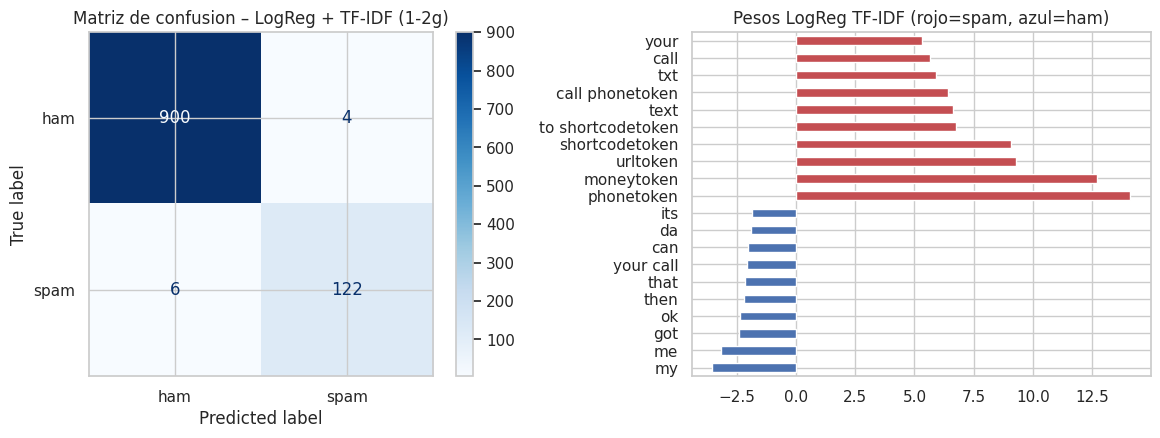

              precision    recall  f1-score   support

         ham     0.9934    0.9956    0.9945       904
        spam     0.9683    0.9531    0.9606       128

    accuracy                         0.9903      1032
   macro avg     0.9808    0.9744    0.9776      1032
weighted avg     0.9903    0.9903    0.9903      1032



In [36]:
best = res_df.index[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_te, preds[best], display_labels=["ham", "spam"], ax=ax[0], cmap="Blues")
ax[0].set_title(f"Matriz de confusion – {best}")

lr = models["LogReg + TF-IDF (1-2g)"]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["vec"].get_feature_names_out())
pd.concat([coefs.nsmallest(10), coefs.nlargest(10)]).plot.barh(ax=ax[1],
    color=["#4C72B0"] * 10 + ["#C44E52"] * 10, title="Pesos LogReg TF-IDF (rojo=spam, azul=ham)")
plt.tight_layout(); plt.show()
print(classification_report(y_te, preds[best], target_names=["ham", "spam"], digits=4))

In [39]:
te = df.iloc[idx_te].assign(pred=preds[best], y=y_te)
print("FALSOS NEGATIVOS (fraude que se escapo):")
for t in te[(te.y == 1) & (te.pred == 0)].clean.head(6): print("  •", t[:120])
print("\nFALSOS POSITIVOS (legitimo bloqueado):")
for t in te[(te.y == 0) & (te.pred == 1)].clean.head(6): print("  •", t[:120])

FALSOS NEGATIVOS (fraude que se escapo):
  • SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Reply A
  • Sorry I missed your call let's talk when you have the time. I'm on 07090201529
  • Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit request after expiry. R
  • Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we g
  • dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you th
  • Hi this is Amy, we will be sending you a free phone number in a couple of days, which will give you an access to all the

FALSOS POSITIVOS (legitimo bloqueado):
  • I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to <#>
  • Please protect yourself from e-threats. SIB never asks for sensitive information like

### Analisis (clasificacion)

- La regresion logistica con TF-IDF de palabras es el mejor modelo (F1 0,9606, precision 0,9683, recall 0,9531), detecta 122 de 128 fraudes y bloquea solo 4 de 904 mensajes legitimos, quitar stopwords baja el recall a 0,9453, lo que confirma que palabras como "your" aportan señal
- Los embeddings tienen el mismo recall pero la peor precision (0,8714, unos 18 falsos positivos), porque confunden mensajes legitimos que hablan de dinero u ofertas con fraude, y Naive Bayes es el baseline mas debil (F1 0,9407)
- Los pesos del modelo son coherentes con el analisis previo, los placeholders "phonetoken", "moneytoken", "urltoken" y "shortcodetoken" son los mas fuertes hacia spam, junto con bigramas de accion como "call phonetoken", mientras que "my", "me" y "ok" empujan hacia ham
- Los falsos negativos son fraudes sin telefono premium ni monto (horoscopos, contenido para adultos, mensajes que imitan un tono personal), y dos de los cuatro falsos positivos son avisos de seguridad de bancos, que comparten vocabulario con el fraude


## Translation (traduccion automatica)
Se usan modelos MarianMT de Helsinki-NLP, entrenados con el corpus paralelo OPUS.

Experimentos:
1. Traduccion inlges a español de mensajes fraudulentos y del resumen del incidente, verificando si se conservan numeros y URLS
2. Robustez por retrotraduccion ingles a español a ingles produce paráfrasis naturales del mismo mensaje

In [40]:
tr_en_es = pipeline("translation", model="Helsinki-NLP/opus-mt-en-es", device=DEVICE)
tr_es_en = pipeline("translation", model="Helsinki-NLP/opus-mt-es-en", device=DEVICE)

def translate(pipe, texts, bs=16):
    return [o["translation_text"] for o in pipe(list(texts), batch_size=bs, max_length=256)]

IOC_TOKEN_RE = re.compile(r"\d{3,}|https?://\S+|www\.\S+|£\s?\d+")
demo = df[df.label == "spam"].clean.sample(6, random_state=3).tolist()
demo_es = translate(tr_en_es, demo)
tr_rows = []
for en, es in zip(demo, demo_es):
    iocs = set(IOC_TOKEN_RE.findall(en))
    kept = sum(i.replace(" ", "") in es.replace(" ", "") for i in iocs)
    tr_rows.append({"ingles": en, "español": es, "IOCs conservados": f"{kept}/{len(iocs)}" if iocs else "—"})
display(pd.DataFrame(tr_rows))

print("\nResumen del incidente traducido al español:\n", wrap(translate(tr_en_es, [abstractive])[0]))

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/312M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/312M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

...

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


,ingles,español,IOCs conservados
0,(Bank of Granite issues Strong-Buy) EXPLOSIVE PICK FOR OUR MEMBERS *****UP OVER 300% *********** Nasdaq Symbol CDGT ...,(Banco de granito emite Strong-Buy) PICK EXPLOSIVO PARA NUESTROS MIEMBROS **** UP MÁS del 300% ********* **** Símbol...,1/1
1,URGENT! We are trying to contact U. Todays draw shows that you have won a £2000 prize GUARANTEED. Call 09066358361 f...,¡URGENTE! Estamos tratando de contactar con U. Todays muestra que usted ha ganado un premio £2000 GARANTIZADO. Llame...,2/2
2,Am new 2 club & dont fink we met yet Will B gr8 2 C U Please leave msg 2day wiv ur area 09099726553 reply promised C...,"Soy nuevo 2 club & dont fink nos conocimos todavía Will B gr8 2 C U Por favor, deje msg 2 días wiv ur area 090997265...",3/3
3,Double your mins & txts on Orange or 1/2 price linerental - Motorola and SonyEricsson with B/Tooth FREE-Nokia FREE C...,Doble sus minutos y txts en Orange o 1/2 precio linerental - Motorola y SonyEricsson con B / Tooth FREE-Nokia GRATIS...,1/1
4,Call Germany for only 1 pence per minute! Call from a fixed line via access number 0844 861 85 85. No prepayment. Di...,Llame a Alemania por sólo 1 penique por minuto! Llame desde una línea fija a través del número de acceso 0844 861 85...,2/2
5,"Free-message: Jamster!Get the crazy frog sound now! For poly text MAD1, for real text MAD2 to 88888. 6 crazy sounds ...","Mensaje gratis: ¡Jamster!¡Consigue el sonido loco de la rana ahora! Para texto poli MAD1, para texto real MAD2 a 888...",1/1



Resumen del incidente traducido al español:
 Una campaña de phishing SMS se hizo pasar por Banco Andino , un banco ficticio utilizado en este ejercicio .
Los mensajes se enviaron desde el número +57 300 000 0000 y advirtieron a los destinatarios de que su cuenta
se bloquearía en un plazo de 24 horas a menos que actualizaran su información . La campaña se basa en la
ingeniería social basada en la urgencia y el temor de perder el acceso a la cuenta .


In [41]:
rng = np.random.RandomState(SEED)
te_spam, te_ham = idx_te[y_te == 1], idx_te[y_te == 0]
bt_idx = np.concatenate([rng.choice(te_spam, 75, replace=False), rng.choice(te_ham, 75, replace=False)])
orig_texts = df.clean.values[bt_idx]
y_bt = y[bt_idx]

back = translate(tr_es_en, translate(tr_en_es, orig_texts))
for o, b in list(zip(orig_texts, back))[:4]:
    print("ORIG:", o[:100]); print("BT  :", b[:100]); print()

tfidf_best = models["LogReg + TF-IDF (1-2g)"]
char_best  = models["LinearSVC + TF-IDF char 3-5"]
rows = []
for name, texts in [("original", orig_texts), ("retrotraducido", back)]:
    norm_t = [normalize(t) for t in texts]
    e = st_model.encode(list(texts), normalize_embeddings=True)
    for mname, pred in [("LogReg + TF-IDF (1-2g)", tfidf_best.predict(norm_t)),
                        ("LinearSVC + TF-IDF char 3-5", char_best.predict(norm_t)),
                        ("LogReg + embeddings", emb_clf.predict(e))]:
        rows.append({"modelo": mname, "datos": name, "recall_spam": recall_score(y_bt, pred), "f1_spam": f1_score(y_bt, pred)})
bt_df = pd.DataFrame(rows).pivot(index="modelo", columns="datos", values=["recall_spam", "f1_spam"]).round(3)
bt_df[("caída F1", "")] = (bt_df[("f1_spam", "original")] - bt_df[("f1_spam", "retrotraducido")]).round(3)
display(bt_df)

ORIG: "For the most sparkling shopping breaks from 45 per person; call 0121 2025050 or visit www.shortbrea
BT  : "For the brightest shopping breaks of 45 per person; call 0121 20205050 or visit www.shortbreaks.org

ORIG: Sorry! U can not unsubscribe yet. THE MOB offer package has a min term of 54 weeks> pls resubmit req
BT  : Sorry! U cannot unsubscribe yet. The MOB offer package has a minimum period of 54 weeks> pls resend 

ORIG: New TEXTBUDDY Chat 2 horny guys in ur area 4 just 25p Free 2 receive Search postcode or at gaytextbu
BT  : New TEXTOBUDDY Chat 2 horny guys in zone 4 only 25p Free 2 receive Search for zip code or on gaytext

ORIG: Customer service announcement. We recently tried to make a delivery to you but were unable to do so,
BT  : Customer Service Announcement. Recently we tried to make a delivery to you, but were not able to do 



recall_spam                 f1_spam  \
datos                          original retrotraducido original   
modelo                                                            
LinearSVC + TF-IDF char 3-5        0.96           0.96    0.973   
LogReg + TF-IDF (1-2g)             0.96           0.96    0.966   
LogReg + embeddings                0.96           0.96    0.966   

                                           caída F1  
datos                       retrotraducido           
modelo                                               
LinearSVC + TF-IDF char 3-5          0.973    0.000  
LogReg + TF-IDF (1-2g)               0.973   -0.007  
LogReg + embeddings                  0.960    0.006

### Analisis (traduccion)

- Los seis mensajes traducidos al español conservan todos sus numeros y enlaces, pero la calidad baja con el lenguaje SMS, las abreviaturas quedan sin traducir
- El resumen del incidente se traduce con buena calidad y conserva el telefono y el plazo de 24 horas, lo que muestra que el modelo funciona bien con texto formal como el de un boletin
- La retrotraduccion altero un indicador, el telefono "0121 2025050" volvio como "0121 20205050", un digito inventado que la metrica de conservacion no detecta porque solo revisa la primera traduccion


In [42]:
del tr_en_es, tr_es_en; gc.collect()
if USE_CUDA: torch.cuda.empty_cache()

## Text Generation (modelo de lenguaje causal base)
Aqui se usa DistilGPT-2, un modelo base que solo continua texto prediciendo el siguiente token, sirve para estudiar las estrategias de decodificacion, que determinan la calidad del texto generado


In [43]:
gen = pipeline("text-generation", model="distilgpt2", device=DEVICE)
PROMPT = "Security alert: criminals are sending text messages that"

def distinct_n(texts, n):
    grams = [tuple(t.split()[i:i + n]) for t in texts for i in range(len(t.split()) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

strategies = {
    "greedy":              dict(do_sample=False),
    "beam (k=5)":          dict(do_sample=False, num_beams=5),
    "beam + no_repeat=2":  dict(do_sample=False, num_beams=5, no_repeat_ngram_size=2),
    "top-k=50, T=0.7":     dict(do_sample=True, top_k=50, temperature=0.7),
    "top-p=0.92, T=1.0":   dict(do_sample=True, top_p=0.92, top_k=0, temperature=1.0),
}
gen_rows = []
for name, kw in strategies.items():
    n_ret = 3 if kw.get("do_sample") else 1
    torch.manual_seed(SEED)
    outs = gen(PROMPT, max_new_tokens=50, num_return_sequences=n_ret, pad_token_id=gen.tokenizer.eos_token_id, **kw)
    conts = [o["generated_text"][len(PROMPT):].strip() for o in outs]
    gen_rows.append({"estrategia": name, "distinct-1": distinct_n(conts, 1), "distinct-2": distinct_n(conts, 2)})
    print(f"\n### {name}\n  {wrap(conts[0])}")
display(pd.DataFrame(gen_rows).round(3))

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/353M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



### greedy
  are being sent to the victim's phone number.

### beam (k=5)
  can be used to send text messages that can be used to send text messages that can be used to send text
messages that can be used to send text messages that can be used to send text messages that can be used to
send text messages that can be

### beam + no_repeat=2
  can be used to send a message to the victim. The message can also be sent to a victim by sending a text
message. If the message is not received, the attacker can send the text to another victim using the same
method as the sender.

### top-k=50, T=0.7
  can be used to send messages to other websites.

### top-p=0.92, T=1.0
  can cause problems that can result in cuts in security and Internet security, making it hard for human
operators to determine when a breach poses serious security risks.


,estrategia,distinct-1,distinct-2
0,greedy,1.000,1.000
1,beam (k=5),0.160,0.163
2,beam + no_repeat=2,0.609,1.000
3,"top-k=50, T=0.7",0.864,1.000
4,"top-p=0.92, T=1.0",0.754,0.991


### Analisis (generacion de texto)

- Beam search sin restricciones muestra la degeneracion tipica de los modelos de lenguaje, repite en bucle "can be used to send text messages" y obtiene la diversidad mas baja
- Greedy obtiene diversidad (1,000) pero solo porque genero una frase muy corta antes de terminar, lo que muestra que distinct-n es engañoso con textos breves y debe leerse junto con la longitud del texto
- Añadir no_repeat_ngram_size=2 elimina el bucle y produce el texto mas coherente con el tema (el atacante envia mensajes a la victima)
- A diferencia del LLM, DistilGPT-2 no sigue instrucciones, solo continua el texto y ninguna estrategia produce un mensaje util sobre smishing, la diferencia no es solo de tamaño sino de entrenamiento con instrucciones, y la estrategia de decodificacion determina tanto como el modelo la calidad del resultado

In [44]:
del gen; gc.collect()
if USE_CUDA: torch.cuda.empty_cache()

## Text Mining (mineria de texto)
La minería de texto combina las tecnicas anteriores para descubrir conocimiento no evidente en el corpus, se aplican tres tecnicas sobre el spam:
1. Colocaciones pares de palabras que aparecen juntos mas de lo esperado por azar
2. Modelado de topicos (LDA) descubrir sin supervision las modalidades de fraude del corpus
3. Nubes de palabras comparativas

In [45]:
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

bam = BigramAssocMeasures()
finder = BigramCollocationFinder.from_documents(df[df.label == "spam"].tokens_nosw.tolist())
finder.apply_freq_filter(5)
display(pd.DataFrame({"Top PMI": [" ".join(b) for b in finder.nbest(bam.pmi, 15)],
                      "Top razon de verosimilitud": [" ".join(b) for b in finder.nbest(bam.likelihood_ratio, 15)]}))

,Top PMI,Top razon de verosimilitud
0,cr wb,call phonetoken
1,croydon cr,po box
2,fantastic surprise,please call
3,log onto,account statement
4,secret admirer,national rate
5,shopping spree,valid hrs
6,surprise awaiting,await collection
7,voda numbers,contact u
8,numbers ending,land line
9,reveal thinks,identifier code


In [46]:
from sklearn.decomposition import LatentDirichletAllocation

placeholders = {"urltoken", "emailtoken", "phonetoken", "moneytoken", "numtoken"}
lda_stop = list(sw | placeholders | {"u", "ur", "txt", "text", "call", "now", "get", "p", "per", "c", "min", "msg"})
spam_norm = df.loc[df.label == "spam", "norm"]

cv_lda = CountVectorizer(stop_words=lda_stop, min_df=3, max_df=0.5)
X_lda = cv_lda.fit_transform(spam_norm)
N_TOPICS = 6
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=SEED, learning_method="batch", max_iter=50).fit(X_lda)

vocab_lda = cv_lda.get_feature_names_out()
dominant = lda.transform(X_lda).argmax(axis=1)
topic_tbl = pd.DataFrame([{"topico": k, "mensajes": int((dominant == k).sum()),
                           "palabras clave": ", ".join(vocab_lda[i] for i in comp.argsort()[::-1][:10])}
                          for k, comp in enumerate(lda.components_)])
display(topic_tbl)
print(f"Perplejidad LDA: {lda.perplexity(X_lda):.1f}")

for k in range(N_TOPICS):
    print(f"\nEjemplo topico {k}:", df.loc[df.label == "spam", "clean"].values[np.where(dominant == k)[0][0]][:120])

,topico,mensajes,palabras clave
0,0,124,"stop, shortcodetoken, reply, send, chat, win, cash, xx, chance, end"
1,1,153,"shortcodetoken, free, week, tone, mobile, nokia, send, stop, new, tones"
2,2,96,"free, reply, new, mins, video, nokia, mobile, phone, optout, offer"
3,3,83,"box, urgent, prize, holiday, rate, nd, landline, po, collection, national"
4,4,66,"shortcodetoken, free, mobile, account, private, expires, code, shows, points, identifier"
5,5,120,"claim, prize, guaranteed, award, mobile, service, customer, cash, valid, urgent"


Perplejidad LDA: 354.7

Ejemplo topico 0: SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply

Ejemplo topico 1: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt r

Ejemplo topico 2: XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobile

Ejemplo topico 3: As a valued customer, I am pleased to advise you that following recent review of your Mob No. you are awarded with a £15

Ejemplo topico 4: Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mo

Ejemplo topico 5: WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. C


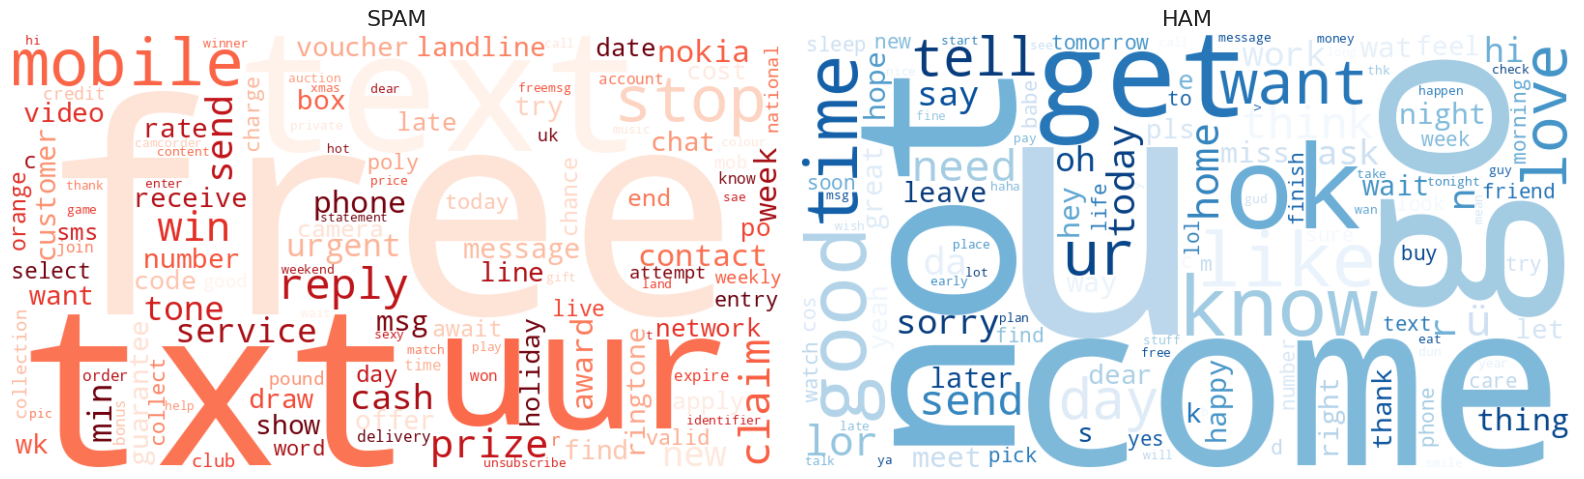

In [47]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, lab, cmap in [(ax[0], "spam", "Reds"), (ax[1], "ham", "Blues")]:
    freqs_wc = Counter(t for ts in df[df.label == lab].lemmas for t in ts)
    a.imshow(WordCloud(width=800, height=450, background_color="white", colormap=cmap,
                       max_words=120).generate_from_frequencies(freqs_wc), interpolation="bilinear")
    a.set_title(lab.upper(), fontsize=16); a.axis("off")
plt.tight_layout(); plt.show()

### Analisis (mineria de texto)

- Las colocaciones por PMI destacan pares raros pero exclusivos de campañas concretas "secret admirer", "fantastic surprise", "croydon cr", mientras que la razon de verosimilitud recupera las formulas fijas que se repiten en todo el spam "call phonetoken", "po box", "await collection", "account statement", "un redeemed points", "moneytoken prize", que pueden usarse como firmas de deteccion
- LDA separa seis modalidades de fraude reconocibles, suscripciones a tonos y contenidos semanales (topico 1, el mas grande con 153 mensajes), concursos y chats con cobro por mensaje (topico 0, 124), premios en efectivo garantizados (topico 5, 120), ofertas de telefonia y contenido movil (topico 2, 96), premios de vacaciones con llamada a linea premium (topico 3, 83) y el pretexto de un estado de cuenta con puntos por vencer (topico 4, 66), este ultimo coincide con una de las campañas detectadas por similitud en la seccion 14
- Los topicos no son del todo limpios, el 3 y el 5 comparten la tematica de premios, y el ejemplo del topico 4 es una oferta de renovacion de movil en lugar de un estado de cuenta, porque LDA asigna probabilidades y un mensaje puede mezclar varias modalidades, los nombres de los topicos son una interpretacion humana
- La nube de palabras resumen visualmente el contraste de todo el laboratorio, el spam esta dominado por el gancho y la accion ("free", "txt", "mobile", "claim", "prize", "stop") y el ham por la conversacion cotidiana ("get", "come", "ok", "know", "love")

## 19. Conclusiones

- Las tecnicas clasicas mostraron que el smishing tiene una huella lingüistica clara, el spam es casi tres veces mas largo, concentra telefonos premium (56 %), montos (52 %) y codigos cortos (32 %) que casi no existen en el ham, usa imperativos en el 53,6 % de los mensajes frente al 19,1 % del ham y se dirige a la victima con palabras como "your" y "won", que la lista estandar de stopwords elimina.
- Las decisiones de preprocesamiento pesan tanto como el modelo, enmascarar numeros en lugar de borrarlos creo los indicadores mas predictivos, Snowball ofrecio el mejor equilibrio entre los algoritmos de stemming, la lematizacion fue mas precisa pero perdio los indicadores numericos, y ninguna herramienta generica (etiquetador POS, NER, lista de stopwords) se transfirio bien al lenguaje del SMS sin revision.
- En clasificacion, un modelo simple de regresion logistica con TF-IDF alcanzo un F1 de 0,9606 y fue el mas explicable, sus pesos coinciden con los indicadores encontrados en el analisis, pero falla con fraudes sin telefono ni monto y marca como fraude algunos avisos de seguridad de bancos, mientras que la similitud semantica permitio agrupar el 32,9 % del spam en campañas que rotan sus numeros de telefono.
- Los modelos generativos aportan explicacion pero no confiabilidad, el LLM justifico bien sus aciertos pero marco como fraude todos los mensajes legitimos e invento indicadores, el QA extractivo evito inventar datos pero respondio "sin respuesta" con alta confianza a una pregunta que si tenia respuesta, y los resumenes perdieron indicadores clave como el dominio malicioso, por lo que en seguridad siempre requieren revision humana.
- Una arquitectura razonable combinaria estas piezas en cascada, reglas para extraer indicadores, un clasificador rapido para decidir, similitud para agrupar campañas, un LLM solo para explicar los casos ya marcados y mineria de topicos periodica para detectar modalidades nuevas.
- La principal limitacion es el corpus, en ingles, del Reino Unido y de hace mas de una decada, donde el fraude se monetizaba con numeros premium y no con enlaces como el smishing actual, el siguiente paso seria construir un corpus de smishing en español colombiano (suplantacion de bancos, entidades del Estado y empresas de mensajeria) y ajustar un modelo multilingüe con esos datos.